# Εργασία 2 – K-Nearest Neighbors & Timeseries Forecasting

# Μέρος 1 – KNN

# Φόρτωση Βιβλιοθηκών

In [ ]:
import holidays
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
import yfinance as yf
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.impute import SimpleImputer
from statsmodels.tsa.stattools import adfuller, kpss, grangercausalitytests

# Φόρτωση dataset

In [2]:
df = pd.read_csv('airline_passenger_satisfaction.csv')

# Έλεγχος δεδομένων στο dataset

In [3]:
df.head()

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


# Επιλογή αριθμητικών τιμών στο dataset και δημιουργία ιστογράμματος (histogram)

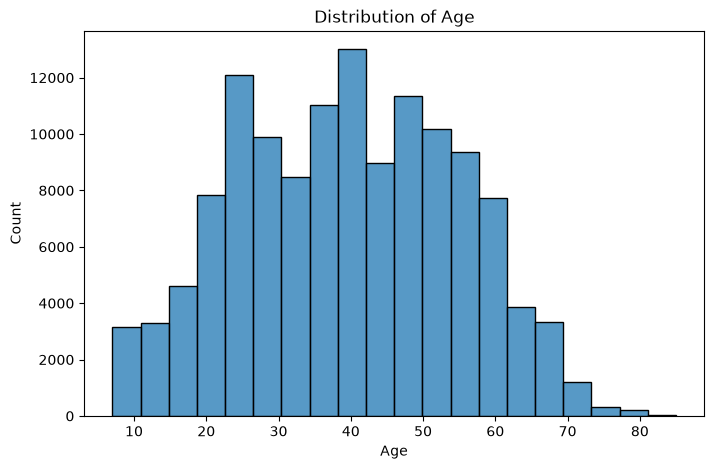

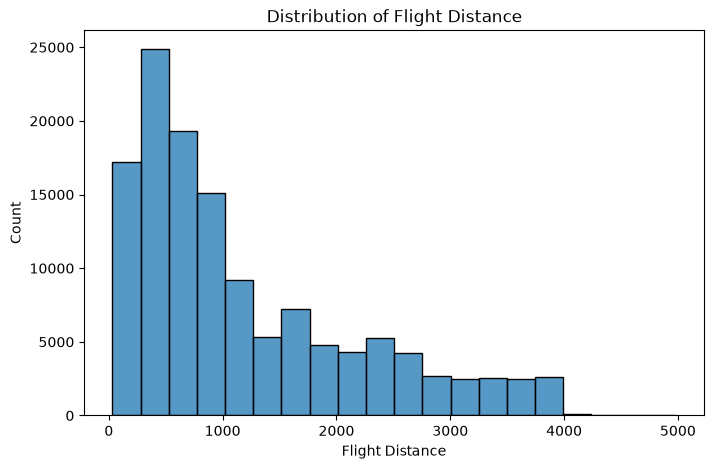

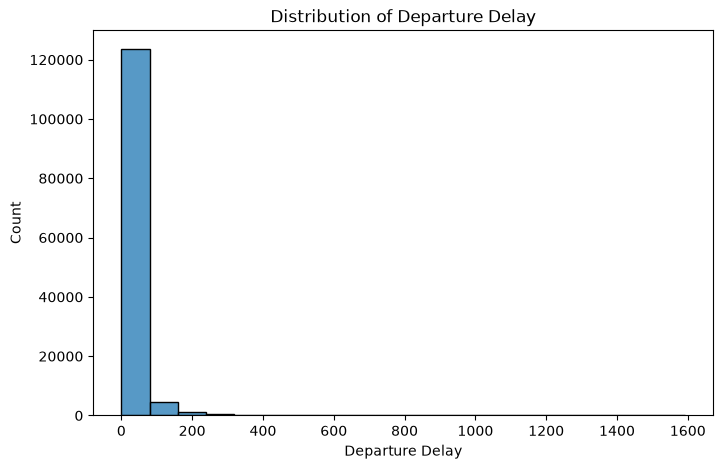

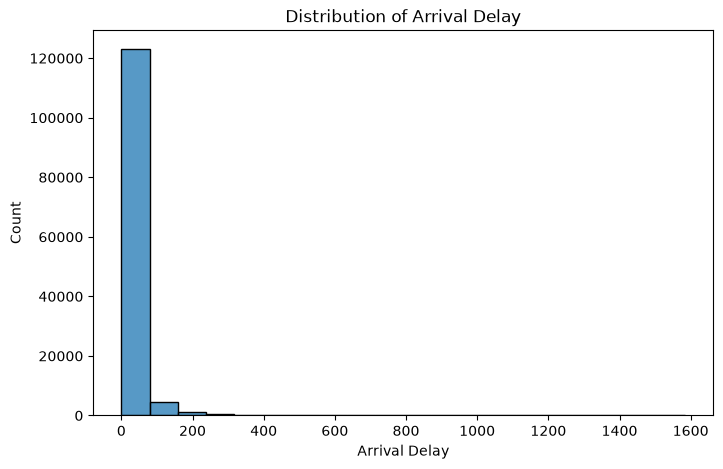

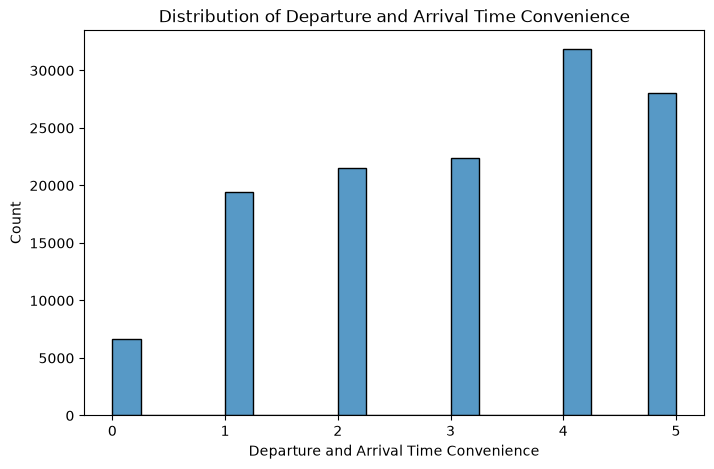

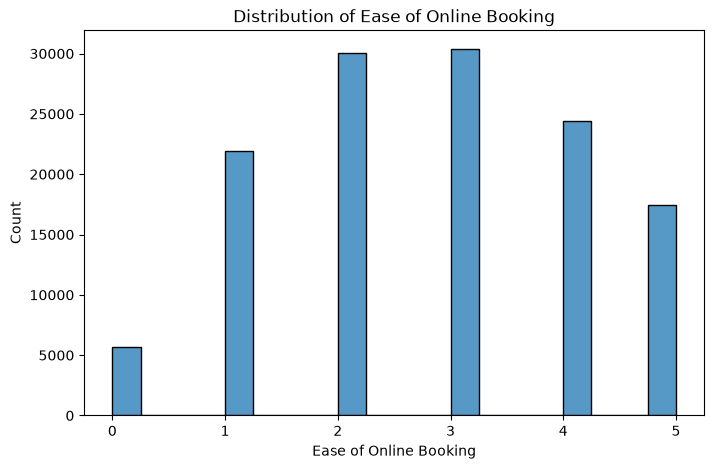

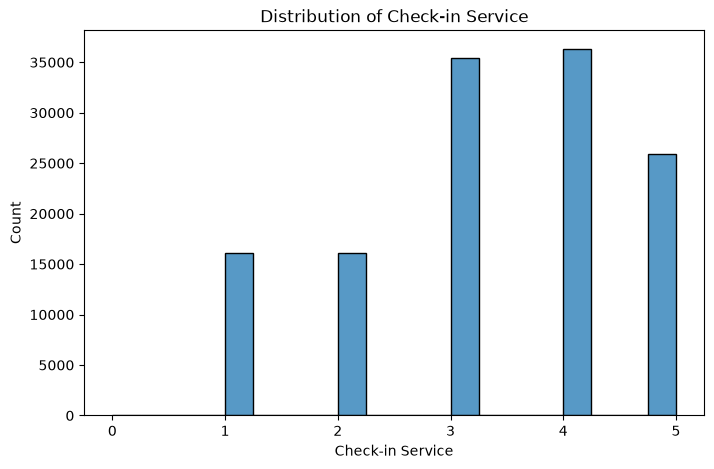

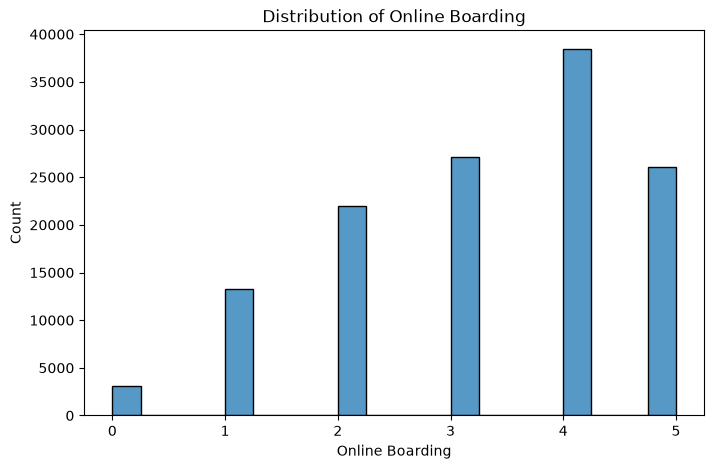

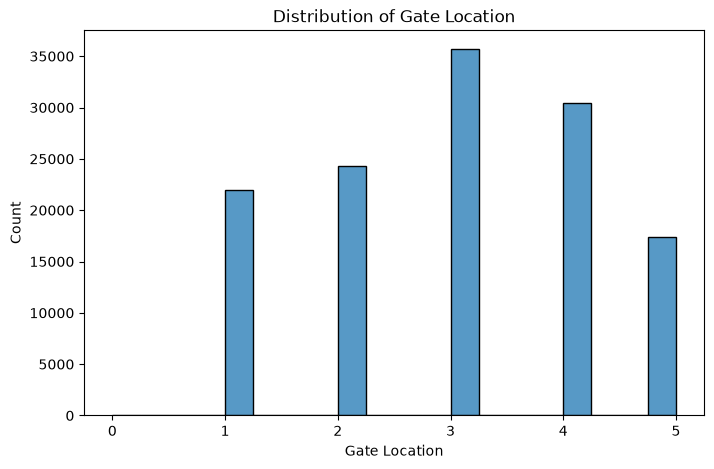

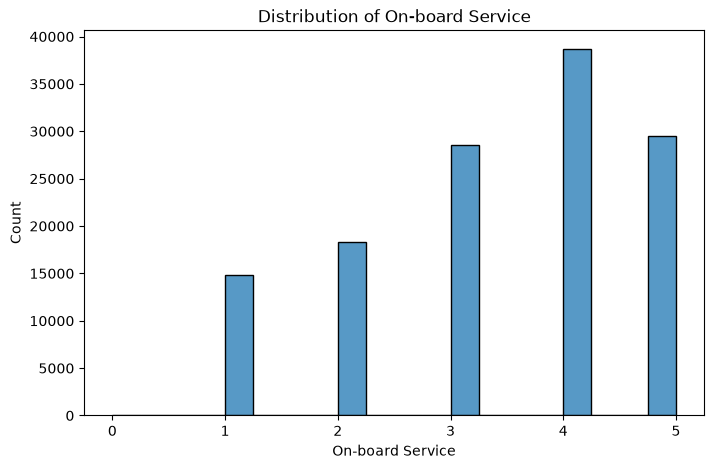

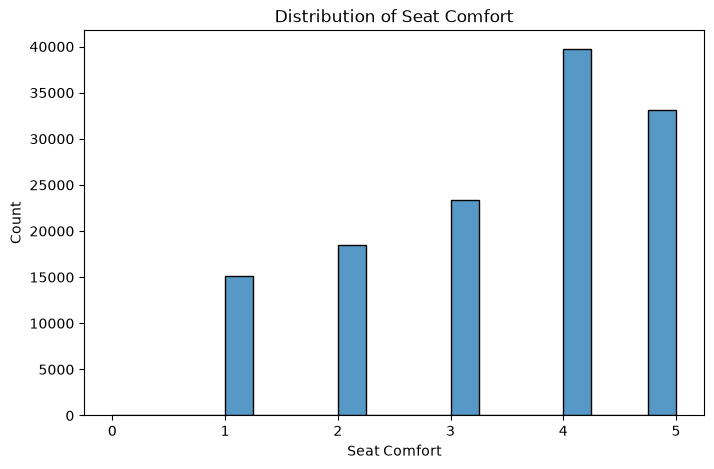

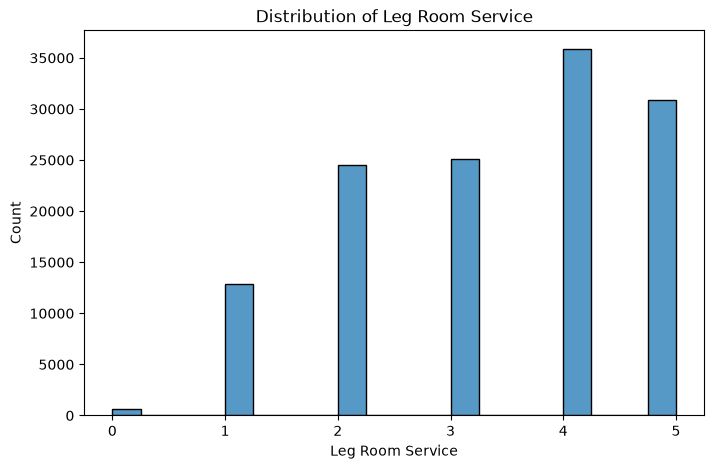

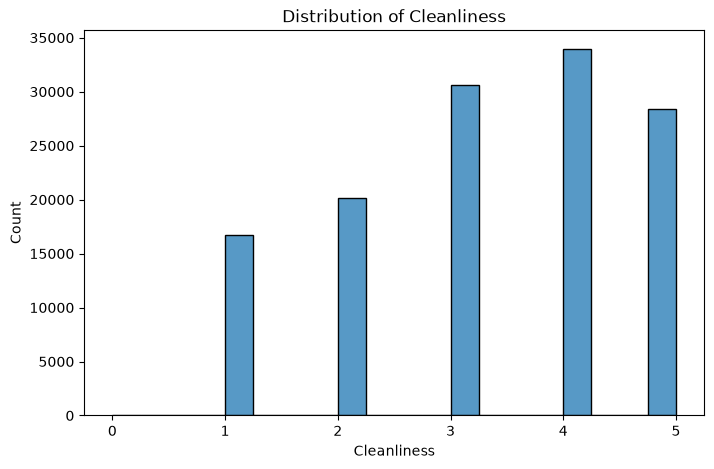

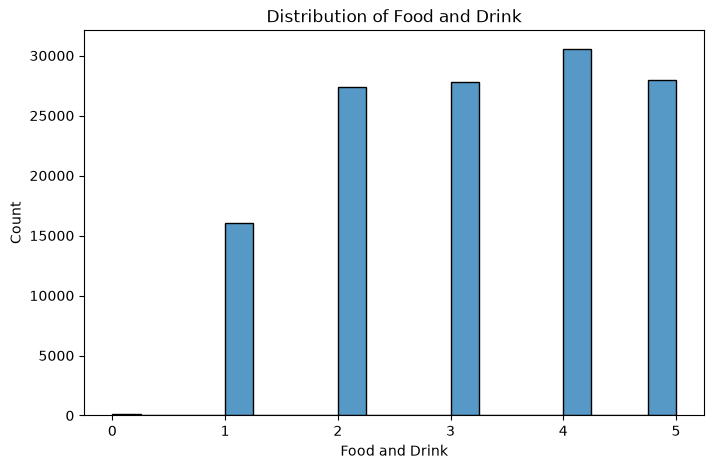

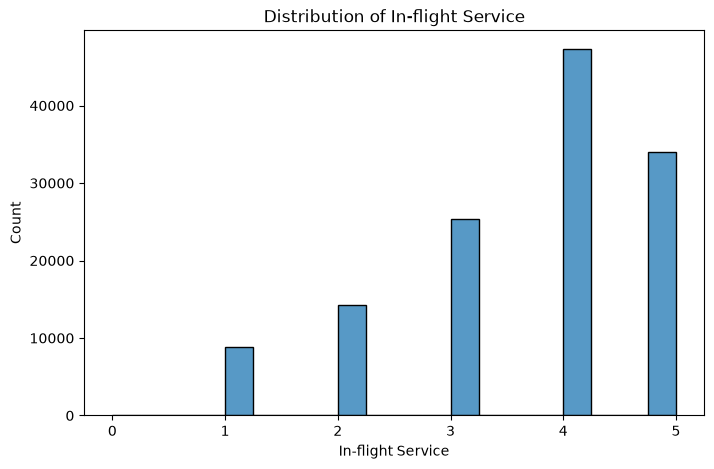

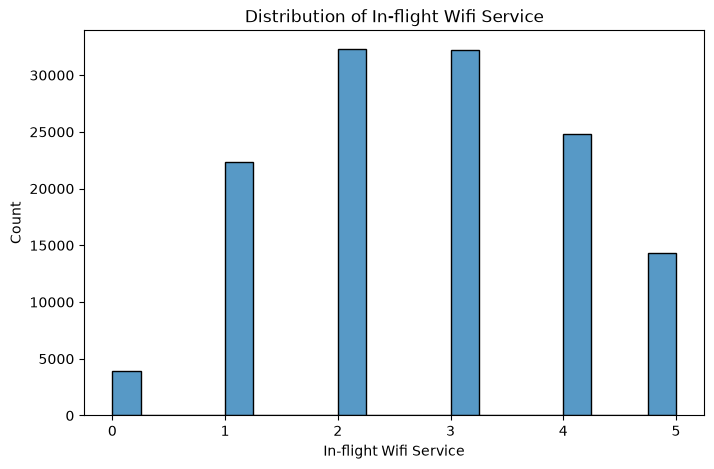

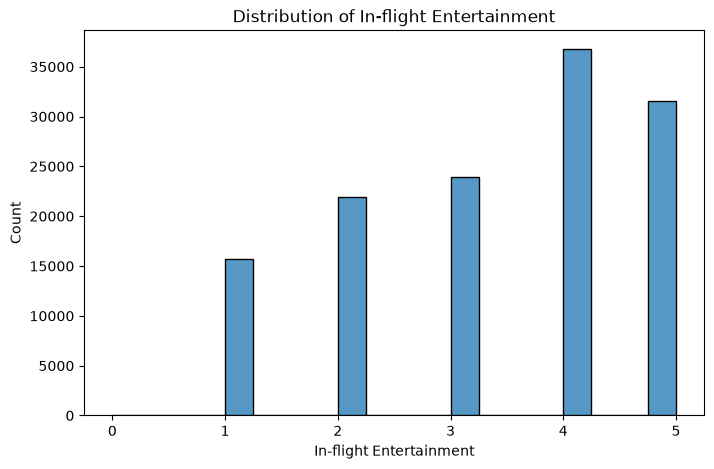

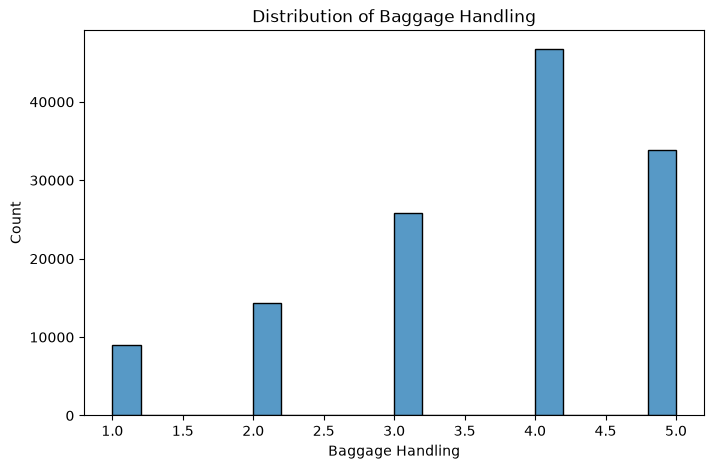

In [4]:
# έχω προσθέσει drop function για την πρώτη στήλη, καθώς έιναι αναγνωριστικό επιβάτη και όχι κατανομή (δεν προσφέρει κάτι το διάγραμμα)
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.drop('ID').to_list()

for col in numerical_cols:

    plt.figure(figsize=(8, 5))
    sns.histplot(data=df, x=col, bins=20)
    plt.title(f'Distribution of {col}')
    plt.show()

# Επιλογή κατηγορικών τιμών στο dataset και δημιουργία ραβδογράμματος (barplot)

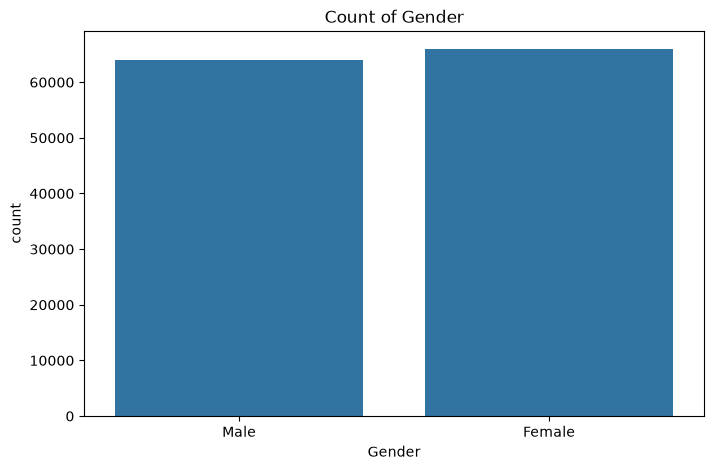

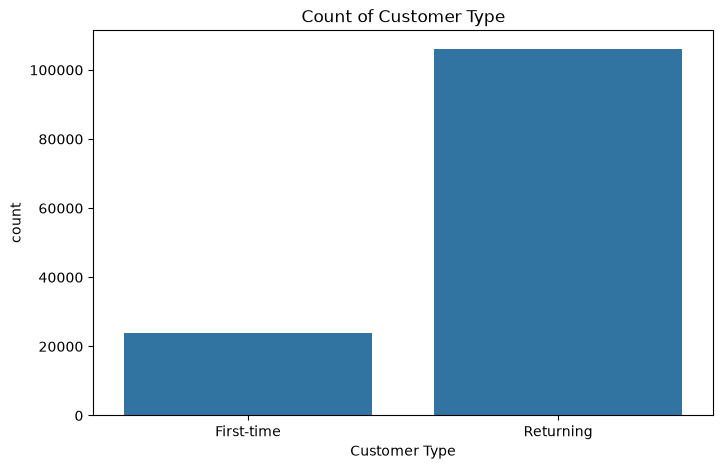

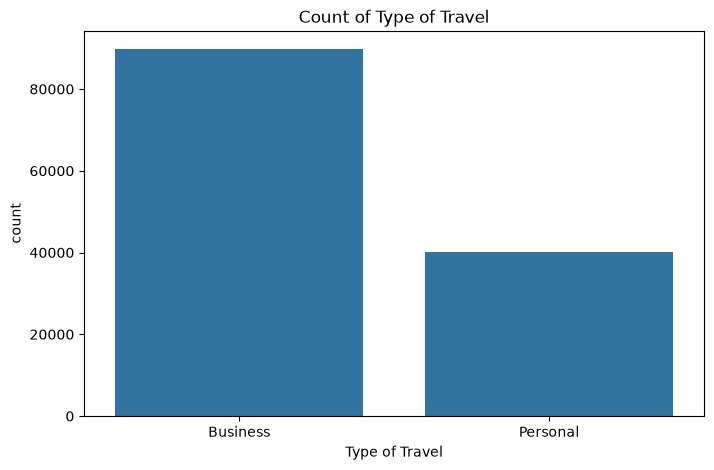

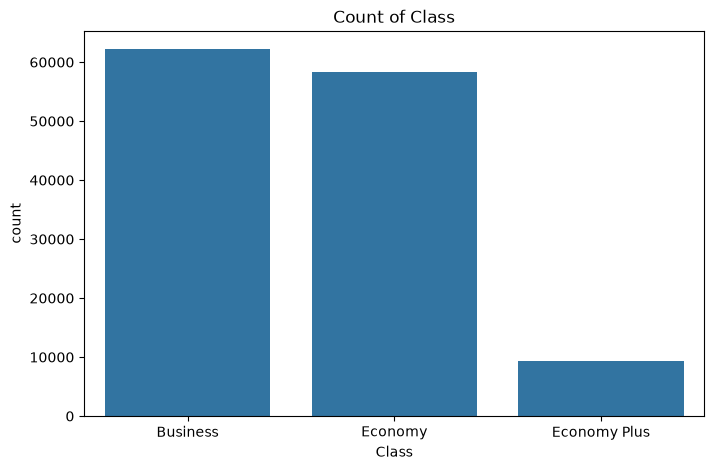

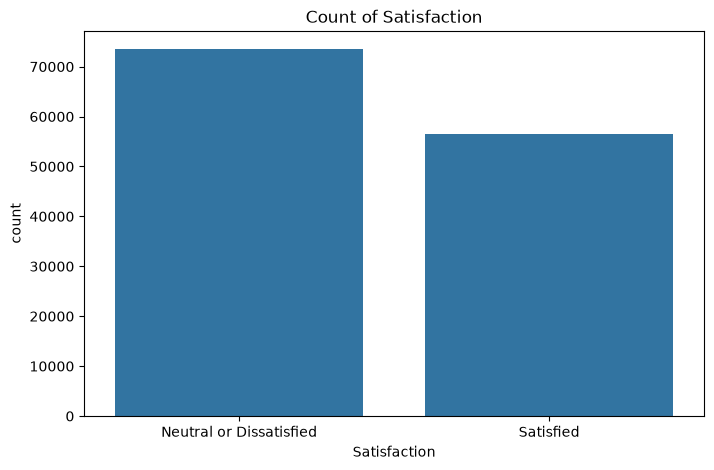

In [5]:
categorical_cols = df.select_dtypes(include=['str', 'category', 'bool']).columns.to_list()

for col in categorical_cols:

    plt.figure(figsize=(8, 5))
    sns.countplot(data=df, x=col)
    plt.title(f'Count of {col}')
    plt.show()

In [6]:
# Έυρεση ποσοστού ικανοποιημένων πελατών (Satisfaction), customer type, type of travel, ticket class 
print(df['Satisfaction'].value_counts(normalize=True)*100)
print(df['Customer Type'].value_counts(normalize=True)*100)
print(df['Type of Travel'].value_counts(normalize=True)*100)
print(df['Class'].value_counts(normalize=True)*100)



Satisfaction
Neutral or Dissatisfied    56.553742
Satisfied                  43.446258
Name: proportion, dtype: float64
Customer Type
Returning     81.690791
First-time    18.309209
Name: proportion, dtype: float64
Type of Travel
Business    69.058362
Personal    30.941638
Name: proportion, dtype: float64
Class
Business        47.859563
Economy         44.894518
Economy Plus     7.245919
Name: proportion, dtype: float64


Από την ανάλυση της στήλης 'Satisfaction', παρατηρούμε ότι η κλάση Neutral or Dissatisfied υπερτερεί με ποσοστό 56,55% έναντι 43,45% της κλάσης Satisfied. Επομένως, διακρίνεται μια μικρή ανισορροπία μεταξύ των δύο κλάσεων.

Επιπλέον, παρατηρούμε ανισορροπία και στις ακόλουθες κλάσεις: 

Customer Type - οι περισσότεροι πελάτες (81,69%) έχουν ξαναχρησιμοποίήσει την DWS Airlines (Returning customers)

Type of Travel - οι περισσότεροι πελάτες (69,06%) βρίσκονται σε επαγγελματικό ταξίδι

Class - οι πελάτες χωρίζονται σε Business Class και Economy Class σε παρόμοια ποσοστά (47,86% και 44,89% αντίστοιχα) με μόλις 7,25% σε θέσεις Economy Plus 



# Τεχνικές κωδικοποίησης κατηγορικών μεταβλητών

In [7]:
# Δημιουργώ αντίγραφο του αρχικού dataset 
df_encoded = df.copy()

# Δυαδική κωδικοποίηση (binary encoding)
df_encoded['Gender'] = df_encoded['Gender'].map({'Male':0, 'Female': 1})

df_encoded['Customer Type'] = df_encoded['Customer Type'].map({'First-time':0, 'Returning': 1})

df_encoded['Type of Travel'] = df_encoded['Type of Travel'].map({'Personal':0, 'Business': 1})

# Label encoding for target
df_encoded['Satisfaction'] = df_encoded['Satisfaction'].map({
    'Neutral or Dissatisfied': 0,
    'Satisfied': 1
})

df_encoded = pd.get_dummies(
    df_encoded,
    columns=['Class'],
    dtype=int
)


# Έλεγχος νέου κωδικοποιημένου dataset
df_encoded.head()


,ID,Gender,Age,Customer Type,Type of Travel,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,Ease of Online Booking,...,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction,Class_Business,Class_Economy,Class_Economy Plus
0,1,0,48,0,1,821,2,5.0,3,3,...,5,5,5,3,5,5,0,1,0,0
1,2,1,35,1,1,821,26,39.0,2,2,...,5,3,5,2,5,5,1,1,0,0
2,3,0,41,1,1,853,0,0.0,4,4,...,5,5,3,4,3,3,1,1,0,0
3,4,0,50,1,1,1905,0,0.0,2,2,...,4,4,5,2,5,5,1,1,0,0
4,5,1,49,1,1,3470,0,1.0,3,3,...,5,4,3,3,3,3,1,1,0,0


Για την κωδικοποίηση των κατηγορικών μεταβλητών χρησιμοποιήθηκαν διαφορετικές τεχνικές ανάλογα με τα χαρακτηριστικά τους. 

Στις δυαδικές μεταβλητές Gender, Customer Type και Type of Travel εφαρμόστηκε δυαδική κωδικοποίηση (0/1). 

Για τη μεταβλητή Class επιλέχθηκε One-Hot Encoding, ώστε να μην εισαχθούν τεχνητές αριθμητικές αποστάσεις μεταξύ των κατηγοριών. Η επιλογή αυτή είναι  σημαντική για αλγορίθμους όπως ο KNN, οι οποίοι βασίζονται στον υπολογισμό αποστάσεων μεταξύ των παρατηρήσεων. Με το One-Hot Encoding αποφεύγεται η αυθαίρετη υπόθεση ότι ορισμένες κατηγορίες βρίσκονται αριθμητικά πιο κοντά μεταξύ τους.

H μεταβλητή Satisfaction κωδικοποιήθηκε σε 0 και 1 για τις δύο κλάσεις της.

# Δημιουργία Numpy arrays 

In [8]:
input_df = df_encoded.drop(columns=['Satisfaction', 'ID'])
targets_df = df_encoded['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((129880, 24), (129880,))

# Χωρισμός συνόλου εκπαίδευσης σε 70-30 % train-test

In [9]:
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((90916, 24), (90916,), (38964, 24), (38964,))

In [10]:

arrival_idx = input_df.columns.get_loc('Arrival Delay')

imputer = SimpleImputer(strategy='median')

x_train[:, [arrival_idx]] = imputer.fit_transform(
    x_train[:, [arrival_idx]]
)

x_test[:, [arrival_idx]] = imputer.transform(
    x_test[:, [arrival_idx]]
)

# Κανονικοποίηση μόνο στις αριθμητικές μεταβλητές

In [11]:
numerical_cols = df.select_dtypes(include='number').columns.drop('ID').tolist()

numerical_indices = input_df.columns.get_indexer(numerical_cols)

scaler = StandardScaler()

x_train_scaled = x_train.copy()
x_test_scaled = x_test.copy()

x_train_scaled[:, numerical_indices] = scaler.fit_transform(x_train[:, numerical_indices])
x_test_scaled[:, numerical_indices] = scaler.transform(x_test[:, numerical_indices])

Για την κανονικοποίηση των αριθμητικών μεταβλητών επιλέχθηκε η μέθοδος StandardScaler (Z-score), καθώς οι μεταβλητές του dataset έχουν διαφορετικές κλίμακες τιμών. Με τη συγκεκριμένη μέθοδο, οι τιμές μετασχηματίζονται ώστε να έχουν μέση τιμή 0 και τυπική απόκλιση 1. 

Αυτό είναι σημαντικό κυρίως για αλγορίθμους όπως ο KNN, που βασίζονται στον υπολογισμό αποστάσεων, καθώς διαφορετικά οι μεταβλητές με μεγαλύτερες τιμές θα μπορούσαν να επηρεάζουν περισσότερο το αποτέλεσμα.    

Η κανονικοποίηση εφαρμόστηκε μόνο στις αριθμητικές μεταβλητές, ενώ οι κατηγορικές διατηρήθηκαν στην κωδικοποιημένη μορφή τους. Επίσης, ο μέσος όρος και η τυπική απόκλιση υπολογίστηκαν μόνο από το training set και στη συνέχεια χρησιμοποιήθηκαν για την κανονικοποίηση του test set. Με αυτόν τον τρόπο αποφεύγεται το data leakage, δηλαδή η χρήση πληροφοριών από τα δεδομένα ελέγχου κατά την προετοιμασία του μοντέλου.  

# Ταξινομητής KNN 

In [12]:
# Αριθμός παραδειγμάτων (training samples)
N = len(x_train_scaled)

k_values = [3, 5, 15, 51, 151, int(np.sqrt(N))]

weight_options = ['uniform', 'distance']

results = []

for k in k_values:
    for weight in weight_options:

        knn = KNeighborsClassifier(
            n_neighbors=k,
            weights=weight,
            metric='euclidean',
            n_jobs=-1
        )

        knn.fit(x_train_scaled, y_train)

        train_accuracy = knn.score(x_train_scaled, y_train)
        test_accuracy = knn.score(x_test_scaled, y_test)

        results.append({
            'k': k,
            'weights': weight,
            'Train Accuracy': train_accuracy,
            'Test Accuracy': test_accuracy
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,k,weights,Train Accuracy,Test Accuracy
0,3,uniform,0.9589,0.9243
1,3,distance,1.0000,0.9243
2,5,uniform,0.9496,0.9278
3,5,distance,1.0000,0.9279
4,15,uniform,0.9349,0.9284
5,15,distance,1.0000,0.9288
6,51,uniform,0.9238,0.9222
7,51,distance,1.0000,0.9228
8,151,uniform,0.9133,0.9124
9,151,distance,1.0000,0.9137


# Εύρεση καλύτερου συνδυασμού 

In [13]:
best_model = results_df.loc[results_df['Test Accuracy'].idxmax()]

print('Καλύτερος συνδυασμός:')
print(best_model)

Καλύτερος συνδυασμός:
k                       15
weights           distance
Train Accuracy         1.0
Test Accuracy     0.928755
Name: 5, dtype: object


Σύμφωνα με τη σύγκριση των 12 συνδυασμών KNN προκύπτει ότι η μεγαλύτερη ακρίβεια στο test set επιτυγχάνεται για k=15 και weigths='distance', με ποσοστό 92,88%.

Παρατηρούμε ότι η ακρίβεια βελτιώνεται όσο αυξάνεται το k μέχρι τους 15 γείτονες, ενώ στη συνέχεια μειώνεται.

Η επιλογή 'distance' δίνει οριακά καλύτερο αποτέλεσμα σε σχέση με τη 'uniform', καθώς οι κοντινότεροι γείτονες αποκτούν μεγαλύτερη βαρύτητα στην πρόβλεψη.

Ταυτόχρονα, παρατηρούμε ότι με τη συγκεκριμένη επιλογή το Train Accuracy φτάνει το 100% σε όλους τους συνδυασμούς, χωρίς όμως να επιτυγχάνεται αντίστοιχη ακρίβεια στο test set. Αυτό δείχνει ότι η επίδοση στα δεδομένα εκπαίδευσης δεν αντικατοπτρίζει απαραίτητα την ικανότητα γενίκευσης του μοντέλου.

# Μέρος 2 – Πρόβλεψη Χρονοσειρών

In [14]:
ticker = 'DX-Y.NYB'

df = yf.Ticker(ticker).history(period='10y').reset_index(drop=False)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more

In [15]:
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997,0,0.0,0.0
1,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002,0,0.0,0.0
2,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004,0,0.0,0.0
3,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000,0,0.0,0.0
4,2016-11-07 00:00:00-05:00,97.540001,97.870003,97.220001,97.779999,0,0.0,0.0


In [16]:
df = df.drop(columns=['Volume', 'Dividends', 'Stock Splits'], errors='ignore')

df.head()

,Date,Open,High,Low,Close
0,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
1,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
2,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
3,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
4,2016-11-07 00:00:00-05:00,97.540001,97.870003,97.220001,97.779999


# Επεξήγηση Μεταβλητών

Οι τιμές OHLCV απεικονίζουν την διακύμανση ενός χρηματoοικονομικού προϊόντος 

- Open = τιμή με κατά το άνοιγμα των αγορών
- High = μέγιστη τιμή ημέρας
- Low = ελάχιστη τιμή ημέρας
- Close = τιμή κατά το κλείσιμο των αγορών
- Volume = όγκος συναλλαγών

In [17]:
df[['Open', 'High', 'Low', 'Close']].agg(['mean', 'std'])

,Open,High,Low,Close
mean,98.800975,99.101802,98.511010,98.810947
std,4.971745,5.019362,4.915539,4.973281


Για τη στατιστική ανάλυση των δεδομένων υπολογίστηκαν η μέση τιμή (mean) και η τυπική απόκλιση (standard deviation) των μεταβλητών Open, High, Low και Close.

Η μέση τιμή δείχνει το μέσο επίπεδο στο οποίο κινήθηκε η κάθε μεταβλητή κατά την εξεταζόμενη δεκαετία. Η τυπική απόκλιση δείχνει πόσο αποκλίνουν οι ημερήσιες τιμές από τη μέση τιμή τους. Όσο μεγαλύτερη είναι η τυπική απόκλιση, τόσο μεγαλύτερη είναι η διασπορά των τιμών, ενώ μια μικρότερη τυπική απόκλιση δείχνει ότι οι τιμές παραμένουν πιο κοντά στον μέσο όρο.

Οι δύο αυτές μετρήσεις μας βοηθούν να κατανοήσουμε τόσο το γενικό επίπεδο των τιμών του δολαρίου όσο και το εύρος των διακυμάνσεων τους κατά την εξεταζόμενη περίοδο.


In [18]:
fig = px.line(df, x='Date', y=['High', 'Close', 'Low'], title='USD Price Index from 2016 to 2026', width=1400, height=650)
fig.show()

Μια χρονοσειρά είναι μη στάσιμη, όταν οι στατιστικές ιδιότητες της αλλάζουν στο χρόνο. (π.χ. τάση και εποχικότητα)

Από την παρατήρηση του διαγράμματος, οι χρονοσειρές High, Low και Close φαίνεται να είναι μη στάσιμες (non-stationary), καθώς παρουσιάζουν σημαντικές αυξομειώσεις και μεταβολές στην τάση τους κατά την εξεταζόμενη περίοδο. Οι τιμές δεν φαίνεται να κινούνται γύρω από ένα σταθερό μέσο επίπεδο, αλλά μεταβάλλονται με την πάροδο του χρόνου. Επομένως, υπάρχουν ενδείξεις ότι οι στατιστικές ιδιότητες των χρονοσειρών δεν παραμένουν σταθερές. 

# Στατιστικά test ADF και KPSS

Σύμφωνα με τις τεχνικές ADF και KPSS ισχύουν τα παρακάτω:

- ADF p-value	KPSS p-value	Συμπέρασμα
- < 0.05	    ≥ 0.05	      Ένδειξη στασιμότητας
- ≥ 0.05	    < 0.05	      Ένδειξη μη στασιμότητας
- < 0.05	    < 0.05	      Αντικρουόμενα αποτελέσματα
- ≥ 0.05	    ≥ 0.05	      Ασαφές αποτέλεσμα

In [19]:
results = []

for col in ['High', 'Low', 'Close']:

    series = df[col].dropna()

    adf_result = adfuller(series)
    kpss_result = kpss(series, regression='c', nlags='auto')

    results.append({
        'Variable': col,
        'ADF Statistic': adf_result[0],
        'ADF p-value': adf_result[1],
        'KPSS Statistic': kpss_result[0],
        'KPSS p-value': kpss_result[1]
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

/var/folders/36/v1y_hpn90bl4zj2cm56vy0mc0000gn/T/ipykernel_25766/1292746166.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(series)
/var/folders/36/v1y_hpn90bl4zj2cm56vy0mc0000gn/T/ipykernel_25766/1292746166.py:8: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_result = kpss(series, regression='c', nlags='auto')
/var/folders/36/v1y_hpn90bl4zj2cm56vy0mc0000gn/T/ipykernel_25766/1292746166.py:8: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` w

,Variable,ADF Statistic,ADF p-value,KPSS Statistic,KPSS p-value
0,High,-1.8994,0.3323,2.8157,0.01
1,Low,-1.9976,0.2876,2.8655,0.01
2,Close,-1.8933,0.3352,2.8391,0.01


Για τον έλεγχο της στασιμότητας των χρονοσειρών High, Low και Close εφαρμόστηκαν τα στατιστικά τεστ ADF και KPSS, με επίπεδο σημαντικότητας 5%.

Από τα αποτελέσματα του ADF προκύπτει ότι και στις τρεις μεταβλητές το p-value είναι μεγαλύτερο από 0.05 (High: 0.3323, Low: 0.2876, Close: 0.3352). Επομένως, δεν μπορούμε να απορρίψουμε τη μηδενική υπόθεση της ύπαρξης μοναδιαίας ρίζας.

Αντίστοιχα, στο KPSS το p-value είναι 0.01 και για τις τρεις μεταβλητές, επομένως απορρίπτουμε τη μηδενική υπόθεση της στασιμότητας.

Συνεπώς, και τα δύο τεστ δείχνουν ότι οι χρονοσειρές είναι μη στάσιμες, επιβεβαιώνοντας την αρχική εκτίμηση που προέκυψε από την παρατήρηση του γραφήματος.


# Χωρισμός dataset σε train-test split

In [20]:
train_size = 0.7
history_size = 30

num_train_samples = int(df.shape[0]*train_size)
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples - history_size:]

train_df.shape, test_df.shape

((1759, 5), (785, 5))

# Δημιουργία Timeframes

In [21]:
def construct_timeframes(df, H):
    inputs = df.drop(columns=['Date']).to_numpy(dtype=np.float64)
    x = np.array([inputs[i-H: i].flatten() for i in range(H, df.shape[0])])
    y = df['Close'].to_numpy(dtype=np.float64)[H:]
    return x, y

# Επαλήθευση

In [22]:
train_df.head(5)


,Date,Open,High,Low,Close
0,2016-11-01 00:00:00-04:00,98.389999,98.480003,97.639999,97.699997
1,2016-11-02 00:00:00-04:00,97.750000,97.800003,97.180000,97.400002
2,2016-11-03 00:00:00-04:00,97.379997,97.459999,97.040001,97.160004
3,2016-11-04 00:00:00-04:00,97.160004,97.349998,96.889999,97.070000
4,2016-11-07 00:00:00-05:00,97.540001,97.870003,97.220001,97.779999


In [23]:
x_train, y_train = construct_timeframes(train_df, H=4)
print('x:', x_train[0],'\ny:', y_train[0])

x: [98.38999939 98.48000336 97.63999939 97.69999695 97.75       97.80000305
 97.18000031 97.40000153 97.37999725 97.45999908 97.04000092 97.16000366
 97.16000366 97.34999847 96.88999939 97.06999969] 
y: 97.77999877929688


# Μοντέλο Γραμμικής Παλινδρόμησης (Linear Regression)

In [24]:
history_sizes = [3, 5, 10, 20, 30]

results = []

for H in history_sizes:

    train_df = df.iloc[:num_train_samples]
    test_df = df.iloc[num_train_samples-H:]

    x_train, y_train = construct_timeframes(train_df, H)
    x_test, y_test = construct_timeframes(test_df, H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    train_mae = mean_absolute_error(y_train, model.predict(x_train))
    test_mae = mean_absolute_error(y_test, model.predict(x_test))

    results.append({
        'Timeframe': H,
        'Train MAE': train_mae,
        'Test MAE': test_mae
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Timeframe,Train MAE,Test MAE
0,3,0.3095,0.3082
1,5,0.3098,0.3085
2,10,0.3067,0.3109
3,20,0.3026,0.3178
4,30,0.2994,0.3241


# Δημιουργία Ραβδογράμματος

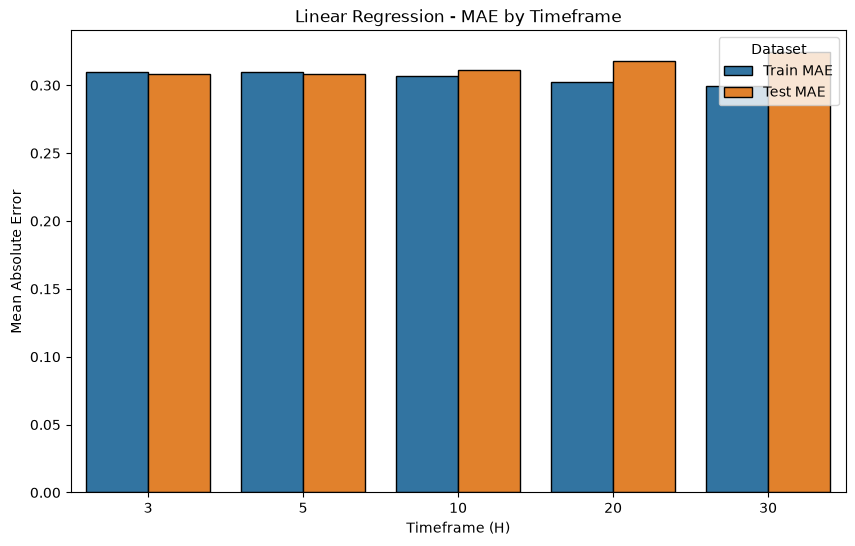

In [25]:
results_plot = results_df.melt(
    id_vars='Timeframe',
    value_vars=['Train MAE', 'Test MAE'],
    var_name='Dataset',
    value_name='MAE'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_plot,
    x='Timeframe',
    y='MAE',
    hue='Dataset',
    edgecolor='black'
)

plt.title('Linear Regression - MAE by Timeframe')
plt.xlabel('Timeframe (H)')
plt.ylabel('Mean Absolute Error')
plt.show()

In [26]:
print('Καλύτερο timeframe:\n', results_df.loc[results_df['Test MAE'].idxmin()])

Καλύτερο timeframe:
 Timeframe    3.000000
Train MAE    0.309507
Test MAE     0.308170
Name: 0, dtype: float64


Για την πρόβλεψη της τιμής κλεισίματος της επόμενης ημέρας χρησιμοποιήθηκε το μοντέλο Linear Regression, με διαφορετικά μεγέθη timeframes (H=3, 5, 10, 20 και 30). Η αξιολόγηση έγινε με τη μετρική Mean Absolute Error (MAE), τόσο στο training όσο και στο test set.

Από τα αποτελέσματα προκύπτει ότι το μικρότερο σφάλμα στο test set παρουσιάζεται για H=3, με MAE=0.3082, ενώ πολύ κοντινή επίδοση έχει και το H=5 (MAE=0.3085). Παρατηρούμε ότι όσο αυξάνεται το μέγεθος του timeframe, το σφάλμα στα δεδομένα εκπαίδευσης γενικά μειώνεται, αλλά στο test set αυξάνεται. 

Επομένως, η χρήση περισσότερων προηγούμενων ημερών δεν οδηγεί απαραίτητα σε καλύτερες προβλέψεις και ενδέχεται να αυξάνει την υπερπροσαρμογή του μοντέλου.


# Σύγκριση πραγματικών και προβλεπόμενων τιμών για H=30

In [27]:
H = 30

# train-test dataframes
train_df = df.iloc[:num_train_samples]
test_df = df.iloc[num_train_samples-H:]

# timeframes
x_train, y_train = construct_timeframes(train_df, H)
x_test, y_test = construct_timeframes(test_df, H)

# model
model = LinearRegression()
model.fit(x_train, y_train)

# predictions
y_train_pred = model.predict(x_train)
y_test_pred = model.predict(x_test)

# corresponding dates
train_dates = train_df['Date'].iloc[H:]
test_dates = test_df['Date'].iloc[H:]

# keep only last 30 train values
train_dates_last30 = train_dates.iloc[-30:]
y_train_last30 = y_train[-30:]
y_train_pred_last30 = y_train_pred[-30:]

In [28]:

fig = go.Figure()

# Train actual - last 30
fig.add_trace(go.Scatter(
    x=train_dates_last30,
    y=y_train_last30,
    mode='lines',
    name='Train Actual (last 30)'
))

# Train predicted - last 30
fig.add_trace(go.Scatter(
    x=train_dates_last30,
    y=y_train_pred_last30,
    mode='lines',
    name='Train Predicted (last 30)'
))

# Test actual
fig.add_trace(go.Scatter(
    x=test_dates,
    y=y_test,
    mode='lines',
    name='Test Actual'
))

# Test predicted
fig.add_trace(go.Scatter(
    x=test_dates,
    y=y_test_pred,
    mode='lines',
    name='Test Predicted'
))

fig.update_layout(
    title='Linear Regression Predictions for Close(t+1) with H=30',
    xaxis_title='Date',
    yaxis_title='Close Price',
    width=1400,
    height=650
)

fig.show()

Για timeframe μεγέθους H=30, οι προβλεπόμενες τιμές του μοντέλου ακολουθούν τη γενική πορεία των πραγματικών τιμών τόσο στο train όσο και στο test set. Ωστόσο, οι προβλέψεις εμφανίζονται πιο ομαλές και δεν αποτυπώνουν πλήρως όλες τις απότομες μεταβολές της χρονοσειράς. Αυτό σημαίνει ότι το μοντέλο καταγράφει ικανοποιητικά τη συνολική τάση, αλλά δυσκολεύεται να προσαρμοστεί ακριβώς στις έντονες ημερήσιες διακυμάνσεις.

# Μετασχηματισμός Log Returns

In [29]:
vars = ['Open', 'High', 'Low', 'Close']
df_logr = df.copy()
df_logr[vars] = np.log(df_logr[vars]/df_logr[vars].shift(1))
df_logr

,Date,Open,High,Low,Close
0,2016-11-01 00:00:00-04:00,NaN,NaN,NaN,NaN
1,2016-11-02 00:00:00-04:00,-0.006526,-0.006929,-0.004722,-0.003075
2,2016-11-03 00:00:00-04:00,-0.003792,-0.003483,-0.001442,-0.002467
3,2016-11-04 00:00:00-04:00,-0.002262,-0.001129,-0.001547,-0.000927
4,2016-11-07 00:00:00-05:00,0.003903,0.005327,0.003400,0.007288
...,...,...,...,...,...
2509,2026-10-26 00:00:00-04:00,0.002065,0.002060,0.000886,0.001472
2510,2026-10-27 00:00:00-04:00,0.002453,0.003326,0.004028,0.003525
2511,2026-10-28 00:00:00-04:00,0.003327,0.000878,0.000588,-0.001271
2512,2026-10-29 00:00:00-04:00,-0.002837,-0.000390,-0.001962,-0.001469


In [30]:
def log_returns_to_absolute_prices(prices, log_returns):
    return prices * np.exp(log_returns)

In [31]:
valid_df = pd.DataFrame({
    'Date': df['Date'].iloc[: 6],
    'Close': df['Close'].iloc[: 6],
    'Close-Log-Returns': df_logr['Close'].iloc[: 6]
})
valid_df

,Date,Close,Close-Log-Returns
0,2016-11-01 00:00:00-04:00,97.699997,NaN
1,2016-11-02 00:00:00-04:00,97.400002,-0.003075
2,2016-11-03 00:00:00-04:00,97.160004,-0.002467
3,2016-11-04 00:00:00-04:00,97.070000,-0.000927
4,2016-11-07 00:00:00-05:00,97.779999,0.007288
5,2016-11-08 00:00:00-05:00,97.860001,0.000818


In [32]:
log_returns_to_absolute_prices(
    prices=valid_df['Close'].iloc[: -1].to_numpy(),
    log_returns=valid_df['Close-Log-Returns'].iloc[1:].to_numpy()
)

array([97.40000153, 97.16000366, 97.06999969, 97.77999878, 97.86000061])

# Log Returns Linear Regression

In [33]:
history_sizes = [3, 5, 10, 20, 30]

log_results = []

for H in history_sizes:

    train_log = df_logr.iloc[1:num_train_samples]
    test_log = df_logr.iloc[num_train_samples-H:]

    x_train, y_train = construct_timeframes(train_log, H)
    x_test, y_test = construct_timeframes(test_log, H)

    model = LinearRegression()
    model.fit(x_train, y_train)

    train_pred = model.predict(x_train)
    test_pred = model.predict(x_test)

    # Previous day's actual Close
    previous_close = df['Close'].shift(1)

    train_idx = train_log.index[H:]
    test_idx = test_log.index[H:]

    # Convert Log-Returns to actual prices
    train_pred_abs = log_returns_to_absolute_prices(
        previous_close.loc[train_idx].to_numpy(),
        train_pred
    )

    test_pred_abs = log_returns_to_absolute_prices(
        previous_close.loc[test_idx].to_numpy(),
        test_pred
    )

    # Actual Close prices
    train_actual = df.loc[train_idx, 'Close'].to_numpy()
    test_actual = df.loc[test_idx, 'Close'].to_numpy()

    train_mae = mean_absolute_error(train_actual, train_pred_abs)
    test_mae = mean_absolute_error(test_actual, test_pred_abs)

    log_results.append({
        'Timeframe': H,
        'Train MAE': train_mae,
        'Test MAE': test_mae
    })

log_results_df = pd.DataFrame(log_results)

display(log_results_df.round(4))

,Timeframe,Train MAE,Test MAE
0,3,0.3098,0.3080
1,5,0.3089,0.3074
2,10,0.3057,0.3136
3,20,0.3017,0.3189
4,30,0.2983,0.3236


In [34]:
comparison_df = results_df.merge(
    log_results_df,
    on='Timeframe',
    suffixes=('_Original', '_LogReturns')
)

display(comparison_df.round(4))

,Timeframe,Train MAE_Original,Test MAE_Original,Train MAE_LogReturns,Test MAE_LogReturns
0,3,0.3095,0.3082,0.3098,0.3080
1,5,0.3098,0.3085,0.3089,0.3074
2,10,0.3067,0.3109,0.3057,0.3136
3,20,0.3026,0.3178,0.3017,0.3189
4,30,0.2994,0.3241,0.2983,0.3236


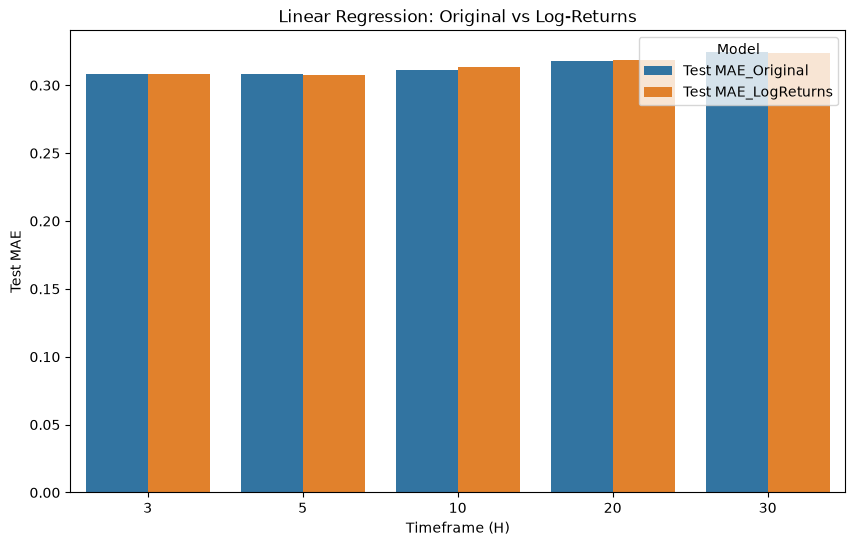

In [35]:
comparison_plot = comparison_df.melt(
    id_vars='Timeframe',
    value_vars=['Test MAE_Original', 'Test MAE_LogReturns'],
    var_name='Model',
    value_name='MAE'
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x='Timeframe',
    y='MAE',
    hue='Model'
)

plt.title('Linear Regression: Original vs Log-Returns')
plt.xlabel('Timeframe (H)')
plt.ylabel('Test MAE')
plt.show()

Για να εξετάσουμε αν ο μετασχηματισμός Log-Returns βελτιώνει την απόδοση του Linear Regression, επαναλάβαμε την εκπαίδευση για τα ίδια timeframes του ερωτήματος 5. Αυτή τη φορά χρησιμοποιήθηκαν οι λογαριθμικές μεταβολές των τιμών αντί για τις αρχικές τιμές.

Οι προβλέψεις μετατράπηκαν ξανά σε πραγματικές τιμές κλεισίματος, ώστε ο υπολογισμός του MAE να γίνει στην ίδια κλίμακα με το αρχικό μοντέλο. Με αυτόν τον τρόπο μπορούμε να συγκρίνουμε τα αποτελέσματα των δύο προσεγγίσεων και να διαπιστώσουμε αν ο μετασχηματισμός συνέβαλε στη μείωση του σφάλματος πρόβλεψης.

Από τα αποτελέσματα παρατηρούμε ότι η χρήση Log-Returns βελτιώνει ελαφρώς το Test MAE για H=3, H=5 και H=30, ενώ για H=10 και H=20 η απόδοση είναι λίγο χειρότερη. Το μικρότερο σφάλμα εμφανίζεται για H=5 με Log-Returns (MAE=0.3074). Ωστόσο, οι διαφορές είναι αρκετά μικρές, επομένως δεν φαίνεται να υπάρχει κάποια σημαντική συνολική βελτίωση σε σχέση με το αρχικό μοντέλο.

# Granger Causality Test

In [36]:
# Train set
train_df = df.iloc[:num_train_samples]

# Log-Returns
data = train_df[['Close', 'Open']].copy()
data = np.log(data / data.shift(1)).dropna()

# Granger Causality Test
results = grangercausalitytests(
    data[['Close', 'Open']],
    maxlag=30,
)

p_values = {
    lag: results[lag][0]['ssr_ftest'][1]
    for lag in range(1, 31)
}

granger_df = pd.DataFrame({
    'Lag (H)': list(p_values.keys()),
    'P-value': list(p_values.values())
})

granger_df['Significant'] = granger_df['P-value'] < 0.05

display(granger_df.round(4))

,Lag (H),P-value,Significant
0,1,0.1934,False
1,2,0.8117,False
2,3,0.5371,False
3,4,0.7925,False
4,5,0.0257,True
5,6,0.5970,False
6,7,0.7316,False
7,8,0.3581,False
8,9,0.2852,False
9,10,0.5157,False


Για να εξετάσουμε αν η μεταβλητή Open είναι χρήσιμη για την πρόβλεψη της Close, εφαρμόσαμε το Granger Causality Test στις λογαριθμικές μεταβολές των δύο μεταβλητών, εξετάζοντας χρονικά βήματα από 1 έως 30.

Από τα αποτελέσματα προκύπτει ότι μόνο για H=5 το p-value είναι μικρότερο από 0.05 (p-value=0.0257). Επομένως, για το συγκεκριμένο μέγεθος ιστορικού απορρίπτουμε τη μηδενική υπόθεση και έχουμε ένδειξη ότι οι προηγούμενες τιμές της Open παρέχουν επιπλέον πληροφορία για την πρόβλεψη της Close.

Για όλα τα υπόλοιπα χρονικά βήματα τα p-values είναι μεγαλύτερα από 0.05, επομένως δεν προκύπτει στατιστικά σημαντική σχέση. Συνολικά, τα αποτελέσματα δείχνουν περιορισμένες ενδείξεις προβλεπτικής χρησιμότητας της Open, καθώς μόνο ένα από τα 30 χρονικά βήματα που εξετάστηκαν ήταν στατιστικά σημαντικό.

Το αποτέλεσμα για H=5 αφορά τον συνολικό έλεγχο των πέντε προηγούμενων χρονικών βημάτων και όχι αποκλειστικά την πέμπτη ημέρα. Επίσης, επειδή εξετάστηκαν 30 διαφορετικά μεγέθη lag, το αποτέλεσμα χρειάζεται προσεκτική ερμηνεία.


# Προσθήκη νέων χαρακτηριστικών

In [37]:
# Original data
df_extended = df.copy()
df_extended['Date'] = pd.to_datetime(df_extended['Date']).dt.tz_localize(None).dt.normalize()

# S&P 500
sp500 = yf.download(
    '^GSPC',
    start=(df_extended['Date'].min() - pd.Timedelta(days=10)).strftime('%Y-%m-%d'),
    end=(df_extended['Date'].max() + pd.Timedelta(days=1)).strftime('%Y-%m-%d'),
    auto_adjust=True,
    progress=False
)

# Keep only closing prices
sp500 = sp500[['Close']].copy()
sp500.columns = ['SP500']
sp500 = sp500.reset_index()
sp500['Date'] = pd.to_datetime(sp500['Date']).dt.tz_localize(None).dt.normalize()

# Match dates and use previously known S&P 500 values
df_extended = df_extended.merge(sp500, on='Date', how='left')
df_extended['SP500'] = df_extended['SP500'].ffill().shift(1)

# Calendar features
df_extended['DayOfWeek'] = df_extended['Date'].dt.dayofweek
df_extended['Month'] = df_extended['Date'].dt.month

us_holidays = holidays.US()

df_extended['Holiday'] = df_extended['Date'].apply(
    lambda date: int(date.date() in us_holidays)
)

df_extended = df_extended.dropna().reset_index(drop=True)

df_extended.head()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more

,Date,Open,High,Low,Close,SP500,DayOfWeek,Month,Holiday
0,2016-11-02,97.750000,97.800003,97.180000,97.400002,2111.719971,2,11,0
1,2016-11-03,97.379997,97.459999,97.040001,97.160004,2097.939941,3,11,0
2,2016-11-04,97.160004,97.349998,96.889999,97.070000,2088.659912,4,11,0
3,2016-11-07,97.540001,97.870003,97.220001,97.779999,2085.179932,0,11,0
4,2016-11-08,97.750000,97.989998,97.550003,97.860001,2131.520020,1,11,0


# Δημιουργία Timeframes με επιπλέον χαρακτηριστικά

In [38]:
def construct_extended_timeframes(data, H):

    historical_cols = ['Open', 'High', 'Low', 'Close', 'SP500']
    future_cols = ['DayOfWeek', 'Month', 'Holiday']

    x = []
    y = []

    for i in range(H, len(data)):

        # Previous H days
        history = data[historical_cols].iloc[i-H:i].to_numpy().flatten()

        # Known calendar features of prediction day
        future = data[future_cols].iloc[i].to_numpy()

        x.append(np.concatenate([history, future]))
        y.append(data['Close'].iloc[i])

    return np.array(x, dtype=float), np.array(y, dtype=float)

In [39]:
H = 30

num_train_extended = int(len(df_extended) * 0.7)

train_extended = df_extended.iloc[:num_train_extended]
test_extended = df_extended.iloc[num_train_extended-H:]

x_train, y_train = construct_extended_timeframes(train_extended, H)
x_test, y_test = construct_extended_timeframes(test_extended, H)

model_extended = LinearRegression()
model_extended.fit(x_train, y_train)

y_train_pred = model_extended.predict(x_train)
y_test_pred = model_extended.predict(x_test)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

print('Train MAE:', round(train_mae, 4))
print('Test MAE:', round(test_mae, 4))

Train MAE: 0.2956
Test MAE: 0.3379


In [40]:
train_dates = train_extended['Date'].iloc[H:]
test_dates = test_extended['Date'].iloc[H:]

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=train_dates.iloc[-30:],
    y=y_train[-30:],
    mode='lines',
    name='Train Actual'
))

fig.add_trace(go.Scatter(
    x=train_dates.iloc[-30:],
    y=y_train_pred[-30:],
    mode='lines',
    name='Train Predicted'
))

fig.add_trace(go.Scatter(
    x=test_dates,
    y=y_test,
    mode='lines',
    name='Test Actual'
))

fig.add_trace(go.Scatter(
    x=test_dates,
    y=y_test_pred,
    mode='lines',
    name='Test Predicted'
))

fig.update_layout(
    title='Linear Regression with Additional Features (H=30)',
    xaxis_title='Date',
    yaxis_title='Close Price',
    width=1200,
    height=650
)

fig.show()

Για H=30, οι προβλεπόμενες τιμές ακολουθούν γενικά την πορεία των πραγματικών τιμών, ωστόσο εξακολουθούν να παρουσιάζονται αποκλίσεις, ιδιαίτερα στις εντονότερες ημερήσιες μεταβολές.

Με την προσθήκη του δείκτη S&P 500 και των ημερολογιακών χαρακτηριστικών, το Train MAE μειώθηκε από 0.2994 σε 0.2956, ενώ το Test MAE αυξήθηκε από 0.3241 σε 0.3379.

Επομένως, παρότι το μοντέλο προσαρμόζεται λίγο καλύτερα στα δεδομένα εκπαίδευσης, η απόδοσή του στα δεδομένα ελέγχου είναι ελαφρώς χειρότερη. Αυτό αποτελεί ένδειξη πιθανής υπερπροσαρμογής και δείχνει ότι η προσθήκη περισσότερων χαρακτηριστικών δεν οδηγεί απαραίτητα σε καλύτερες προβλέψεις.